In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("food-texture.csv")

# Display first 5 rows
print("First 5 Rows:")
print(df.head())

# Dataset shape
print("\nDataset Shape:", df.shape)

# Column names
print("\nColumn Names:")
print(df.columns)

# Dataset information
print("\nDataset Information:")
df.info()

First 5 Rows:
  Unnamed: 0   Oil  Density  Crispy  Fracture  Hardness
0       B110  16.5     2955      10        23        97
1       B136  17.7     2660      14         9       139
2       B171  16.2     2870      12        17       143
3       B192  16.7     2920      10        31        95
4       B225  16.3     2975      11        26       143

Dataset Shape: (50, 6)

Column Names:
Index(['Unnamed: 0', 'Oil', 'Density', 'Crispy', 'Fracture', 'Hardness'], dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     str    
 1   Oil         50 non-null     float64
 2   Density     50 non-null     int64  
 3   Crispy      50 non-null     int64  
 4   Fracture    50 non-null     int64  
 5   Hardness    50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB


In [4]:
# Remove unnecessary index column if present
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# Remove duplicate rows if any
df = df.drop_duplicates()

# Check data types
print("\nData Types:")
print(df.dtypes)

# Check final shape
print("\nFinal Dataset Shape:", df.shape)

Missing Values:
Oil         0
Density     0
Crispy      0
Fracture    0
Hardness    0
dtype: int64

Duplicate Rows: 0

Data Types:
Oil         float64
Density       int64
Crispy        int64
Fracture      int64
Hardness      int64
dtype: object

Final Dataset Shape: (50, 5)


In [5]:
# Descriptive statistics
print("Descriptive Statistics:")
print(df.describe())

# Mean
print("\nMean:")
print(df.mean(numeric_only=True))

# Median
print("\nMedian:")
print(df.median(numeric_only=True))

# Standard deviation
print("\nStandard Deviation:")
print(df.std(numeric_only=True))

# Variance
print("\nVariance:")
print(df.var(numeric_only=True))

Descriptive Statistics:
             Oil     Density     Crispy   Fracture    Hardness
count  50.000000    50.00000  50.000000  50.000000   50.000000
mean   17.202000  2857.60000  11.520000  20.860000  128.180000
std     1.592007   124.49998   1.775571   5.466073   31.127578
min    13.700000  2570.00000   7.000000   9.000000   63.000000
25%    16.300000  2772.50000  10.000000  17.000000  107.250000
50%    16.900000  2867.50000  12.000000  21.000000  126.000000
75%    18.100000  2945.00000  13.000000  25.000000  143.750000
max    21.200000  3125.00000  15.000000  33.000000  192.000000

Mean:
Oil           17.202
Density     2857.600
Crispy        11.520
Fracture      20.860
Hardness     128.180
dtype: float64

Median:
Oil           16.9
Density     2867.5
Crispy        12.0
Fracture      21.0
Hardness     126.0
dtype: float64

Standard Deviation:
Oil           1.592007
Density     124.499980
Crispy        1.775571
Fracture      5.466073
Hardness     31.127578
dtype: float64

Variance:
O

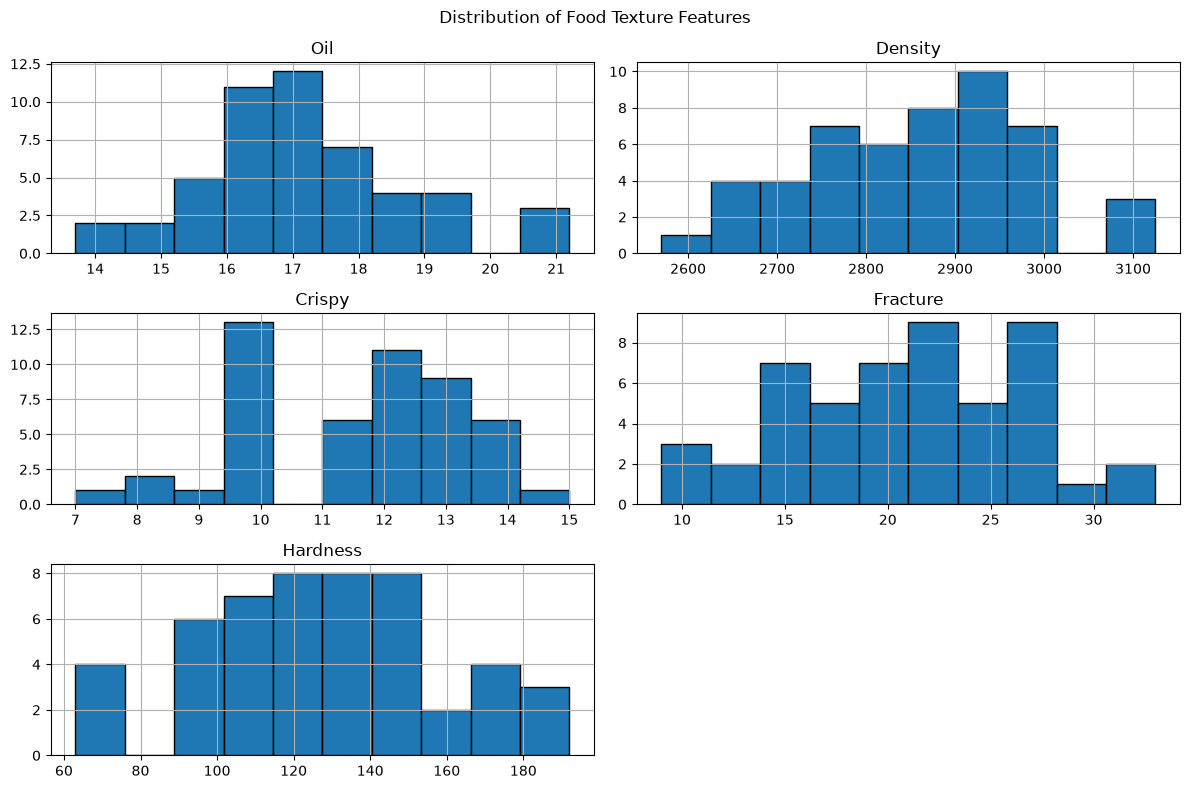

In [8]:
df.hist(figsize=(12, 8), bins=10, edgecolor="black")

plt.suptitle("Distribution of Food Texture Features")
plt.tight_layout()
plt.show()

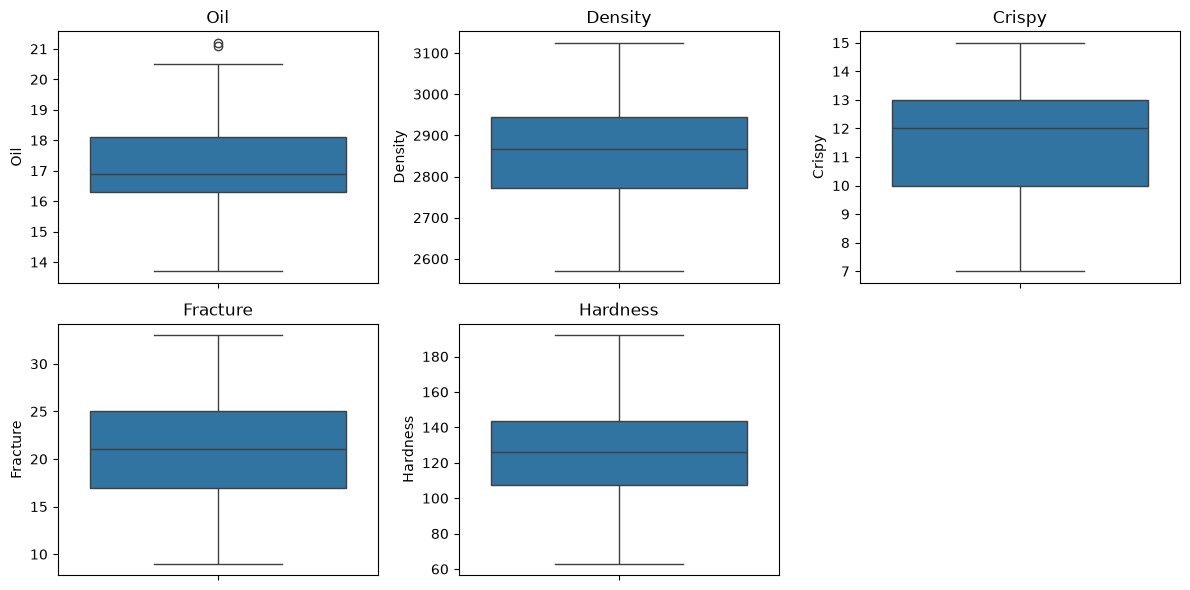

In [5]:
plt.figure(figsize=(12, 6))

for i, column in enumerate(df.columns, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[column])
    plt.title(column)

plt.tight_layout()
plt.show()

Correlation Matrix:
               Oil   Density    Crispy  Fracture  Hardness
Oil       1.000000 -0.750024  0.593086 -0.533739 -0.096045
Density  -0.750024  1.000000 -0.670946  0.572132  0.107937
Crispy    0.593086 -0.670946  1.000000 -0.843965  0.411093
Fracture -0.533739  0.572132 -0.843965  1.000000 -0.373358
Hardness -0.096045  0.107937  0.411093 -0.373358  1.000000


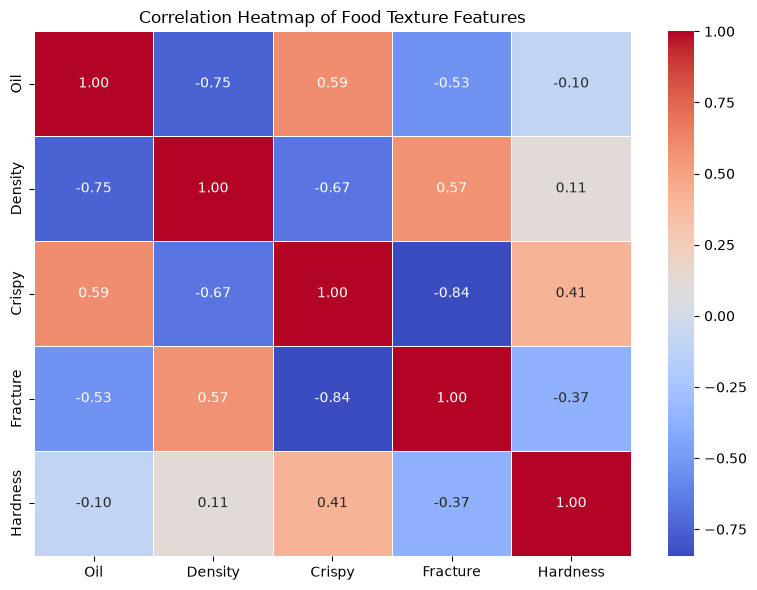

In [6]:
correlation = df.corr(numeric_only=True)

print("Correlation Matrix:")
print(correlation)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Food Texture Features")
plt.tight_layout()
plt.show()

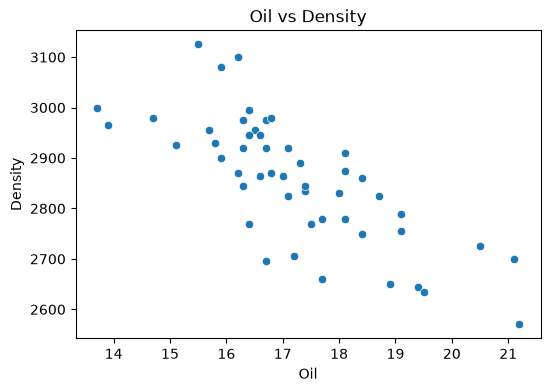

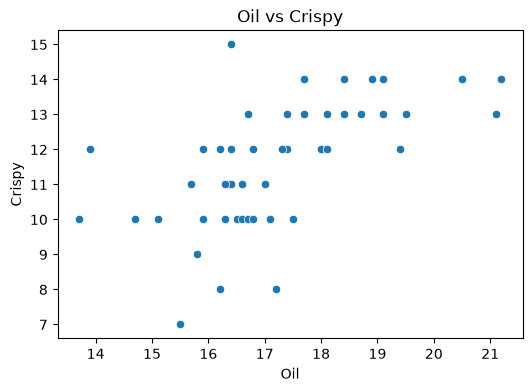

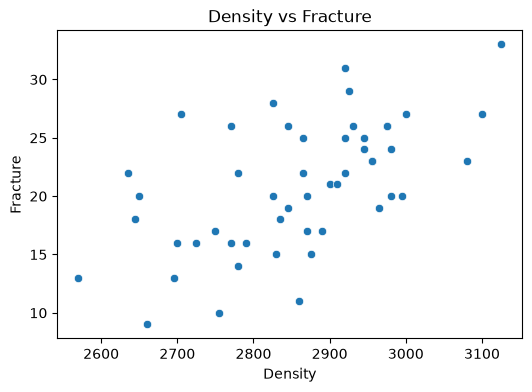

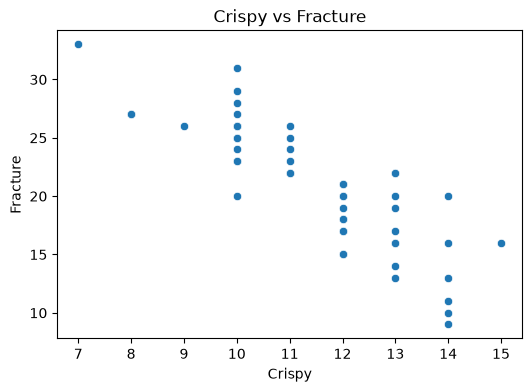

In [7]:
# Oil vs Density
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Oil", y="Density")
plt.title("Oil vs Density")
plt.show()

# Oil vs Crispy
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Oil", y="Crispy")
plt.title("Oil vs Crispy")
plt.show()

# Density vs Fracture
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Density", y="Fracture")
plt.title("Density vs Fracture")
plt.show()

# Crispy vs Fracture
plt.figure(figsize=(6, 4))
sns.scatterplot(data=df, x="Crispy", y="Fracture")
plt.title("Crispy vs Fracture")
plt.show()

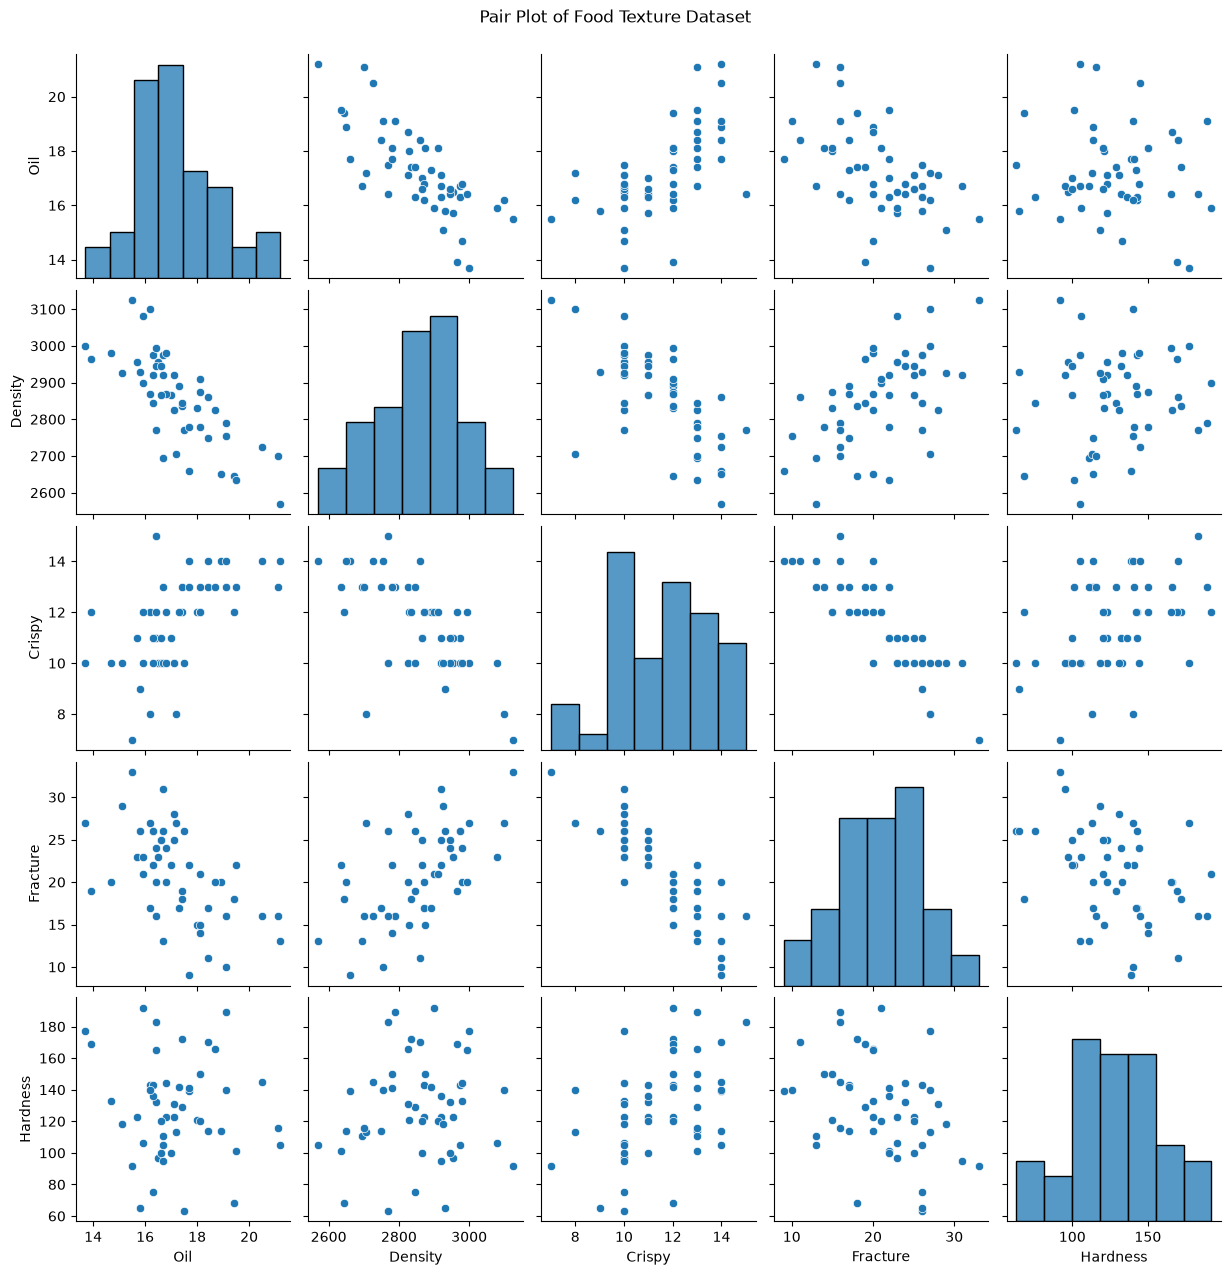

In [8]:
sns.pairplot(df, diag_kind="hist")
plt.suptitle("Pair Plot of Food Texture Dataset", y=1.02)
plt.show()

In [9]:
for column in df.select_dtypes(include=np.number).columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nColumn: {column}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: Oil
Lower Bound: 13.6
Upper Bound: 20.800000000000004
Number of Outliers: 2

Column: Density
Lower Bound: 2513.75
Upper Bound: 3203.75
Number of Outliers: 0

Column: Crispy
Lower Bound: 5.5
Upper Bound: 17.5
Number of Outliers: 0

Column: Fracture
Lower Bound: 5.0
Upper Bound: 37.0
Number of Outliers: 0

Column: Hardness
Lower Bound: 52.5
Upper Bound: 198.5
Number of Outliers: 0


In [10]:
print("========== FINAL EDA SUMMARY ==========")

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nFeature Means:")
print(df.mean(numeric_only=True))

print("\nFeature Correlations:")
print(df.corr(numeric_only=True).round(2))

print("\nEDA Completed Successfully!")

========== FINAL EDA SUMMARY ==========

Number of Rows: 50
Number of Columns: 5

Missing Values:
Oil         0
Density     0
Crispy      0
Fracture    0
Hardness    0
dtype: int64

Duplicate Rows: 0

Feature Means:
Oil           17.202
Density     2857.600
Crispy        11.520
Fracture      20.860
Hardness     128.180
dtype: float64

Feature Correlations:
           Oil  Density  Crispy  Fracture  Hardness
Oil       1.00    -0.75    0.59     -0.53     -0.10
Density  -0.75     1.00   -0.67      0.57      0.11
Crispy    0.59    -0.67    1.00     -0.84      0.41
Fracture -0.53     0.57   -0.84      1.00     -0.37
Hardness -0.10     0.11    0.41     -0.37      1.00

EDA Completed Successfully!


Training Linear Regression Model Upon This Food-Texture .CSV


In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

# Load dataset if the notebook was not run from the top
if "df" not in globals():
    df = pd.read_csv("food-texture.csv")

# Remove identifier column if present before scaling
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# Use only numeric columns for modeling
numeric_df = df.select_dtypes(include=np.number)

scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(numeric_df), columns=numeric_df.columns)

X = df_scaled.drop(columns=["Fracture"])
y = df_scaled["Fracture"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully.")
print("Train score:", model.score(X_train, y_train))
print("Test score:", model.score(X_test, y_test))

Model trained successfully.
Train score: 0.6702695357104435
Test score: 0.8117702229806804
